# PhonoLens · Notebook 2: Fine-tuning & Evaluation
Fine-tunes the wav2vec2 phoneme recogniser to output our 39 phones, then evaluates it against the Notebook 1 baseline on the **unseen Hindi-L1 speakers**.

**Key design choices (worth explaining in the viva)**
- **Targets = what was actually said.** We train on the *annotated* pronunciation, not the dictionary one. Training on dictionary pronunciations would teach the model to "hear" every error as correct.
- **Warm-started output layer.** The new 40-class head (blank + 39 phones) is initialised from the pretrained model's matching espeak phone rows, so training starts from the baseline instead of from random.
- **Speaker-independent.** Train on 15 L2-ARCTIC speakers (+ adult speechocean762 utterances that experts rated fully correct), select on 5 dev speakers, test on the 4 Hindi speakers who are never seen in training.
- **Two evaluation modes.** *Strict* uses the US annotators' labels as-is. *Indian-English-aware* accepts four standard Indian-English vowel realisations (FACE/GOAT monophthongs, schwa for NURSE, rounded LOT) as correct.

**Run:** T4 GPU runtime → run cell 1 (it may restart the runtime once) → Run all. Training takes about 45–75 min. If Colab disconnects, just Run all again: it **resumes from the last finished epoch** saved on Drive.

In [ ]:
# Cell 1: install (restarts the runtime once if needed)
import os
try:
    import datasets
    need_restart = not datasets.__version__.startswith(("2.", "3."))
except ImportError:
    need_restart = True
!pip install -q "datasets>=2.19,<4" librosa soundfile praat-parselmouth g2p_en
if need_restart:
    print("Restarting runtime so the pinned `datasets` version loads. Run the next cells after this.")
    os.kill(os.getpid(), 9)
else:
    print("Packages ready ✅")

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gcsfs 2025.12.0 requires fsspec==2025.12.0, but you have fsspec 2025.3.0 which is incompatible.


In [1]:
# Cell 2: Drive, paths, local data copy
import os, json, shutil, time
from google.colab import drive
drive.mount('/content/drive')

SAVE      = "/content/drive/MyDrive/phonolens_data"
LOCAL     = "/content/data"
MODEL_DIR = f"{SAVE}/models/wav2vec2-xlsr-53-espeak-cv-ft"     # pretrained (Notebook 0)
FT_BEST   = f"{SAVE}/models/phonolens-ft"                      # best fine-tuned model
FT_LAST   = f"{SAVE}/models/phonolens-ft-last"                 # last epoch (for resuming)
FIG, RES  = f"{SAVE}/figures", f"{SAVE}/results"
for d in (FIG, RES, LOCAL):
    os.makedirs(d, exist_ok=True)
for name in ["l2arctic", "speechocean"]:
    if not os.path.exists(f"{LOCAL}/{name}"):
        t = time.time(); shutil.copytree(f"{SAVE}/{name}", f"{LOCAL}/{name}")
        print(f"copied {name} in {time.time()-t:.0f}s")

import torch
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", torch.cuda.get_device_name(0) if DEVICE == "cuda" else "CPU: training would take many hours, switch to a T4 GPU")

Mounted at /content/drive
copied l2arctic in 18s
copied speechocean in 19s
Device: Tesla T4


In [2]:
%%writefile /content/drive/MyDrive/phonolens_data/phonolens_core.py
"""
phonolens_core.py — shared code for the PhonoLens project.

Sections
  1. Phone set (CMU-39 written in IPA) + normalisation of any IPA / ARPAbet input
  2. Alignment (Levenshtein) + mispronunciation detection & diagnosis (MDD) metrics
  3. CTC helpers: greedy decoding, Viterbi forced alignment
  4. Classical speech processing: pre-emphasis, framing, VAD, LPC (Levinson-Durbin), formants
  5. Feedback text for common Indian-English substitutions
"""
from collections import Counter
import numpy as np

# =============================================================================
# 1. PHONE SET
# =============================================================================
# CMU ARPAbet 39-phone set (the one L2-ARCTIC and speechocean762 are labelled in),
# written in IPA so it matches the L2-ARCTIC 'ipa' / 'g2p' columns.
ARPA2IPA = {
    "AA": "ɑ", "AE": "æ", "AH": "ʌ", "AO": "ɔ", "AW": "aʊ", "AY": "aɪ", "EH": "ɛ",
    "ER": "ɝ", "EY": "eɪ", "IH": "ɪ", "IY": "i", "OW": "oʊ", "OY": "ɔɪ", "UH": "ʊ",
    "UW": "u", "B": "b", "CH": "tʃ", "D": "d", "DH": "ð", "F": "f", "G": "ɡ",
    "HH": "h", "JH": "dʒ", "K": "k", "L": "l", "M": "m", "N": "n", "NG": "ŋ",
    "P": "p", "R": "ɹ", "S": "s", "SH": "ʃ", "T": "t", "TH": "θ", "V": "v",
    "W": "w", "Y": "j", "Z": "z", "ZH": "ʒ",
}
PHONES = sorted(set(ARPA2IPA.values()))                     # 39 phones
PH2ID = {p: i + 1 for i, p in enumerate(PHONES)}              # CTC labels: 0 = blank
ID2PH = {i: p for p, i in PH2ID.items()}
VOWELS = {"ɑ", "æ", "ʌ", "ɔ", "aʊ", "aɪ", "ɛ", "ɝ", "eɪ", "ɪ", "i", "oʊ", "ɔɪ", "ʊ", "u"}
MONOPHTHONGS = VOWELS - {"aʊ", "aɪ", "eɪ", "oʊ", "ɔɪ"}

# Marks we throw away (stress, length, tones, most diacritics, syllabicity, ties).
_STRIP = set("ˈˌːˑ̩̯̃ʰʲʷ̥̬̪̺̻͡‿.|-_ ") | {"̩", "̯", "̃", "͡", "˞"}

# Symbol rewrites applied before tokenising. Order matters (longest first).
# Several of these are deliberate accent-fairness decisions: e.g. Indian-English
# monophthongs [e:] / [o:] are mapped onto the FACE / GOAT diphthongs, and a tapped
# or trilled r is mapped onto /ɹ/, so these accent features are NOT counted as errors.
_REWRITES = [
    ("ɝɹ", "ɝ"), ("ɚɹ", "ɝ"), ("ɜɹ", "ɝ"), ("əɹ", "ɝ"),
    ("əʊ", "oʊ"), ("eə", "ɛ"), ("ɪə", "ɪ"), ("ʊə", "ʊ"), ("aɪə", "aɪ"),
    ("ɚ", "ɝ"), ("ɜ", "ɝ"), ("ə", "ʌ"), ("ɐ", "ʌ"), ("ᵻ", "ɪ"), ("ɨ", "ɪ"),
    ("ʉ", "u"), ("ɯ", "u"), ("y", "i"), ("ɒ", "ɑ"), ("ɫ", "l"), ("g", "ɡ"),
    ("ɾ", "ɹ"), ("r", "ɹ"), ("ɻ", "ɹ"), ("ʀ", "ɹ"), ("ʁ", "ɹ"),
    ("ʈ", "t"), ("ɖ", "d"), ("ɳ", "n"), ("ɭ", "l"), ("ʂ", "ʃ"), ("ɕ", "ʃ"), ("ʑ", "ʒ"),
    ("x", "k"), ("q", "k"), ("ç", "h"), ("ɦ", "h"), ("β", "v"), ("ʋ", "v"), ("ɸ", "f"),
    ("c", "k"), ("ɟ", "ɡ"), ("ɲ", "n"), ("ʎ", "l"), ("ʔ", ""),
]
# Single symbols that are only valid as part of a longer phone, or need a default.
_LONE = {"e": "eɪ", "o": "oʊ", "a": "ɑ"}

_PHONES_BY_LEN = sorted(PHONES, key=len, reverse=True)


def _clean(s):
    s = "".join(ch for ch in s if ch not in _STRIP)
    for a, b in _REWRITES:
        s = s.replace(a, b)
    return s


def ipa_to_phones(s, keep_unknown=False):
    """Split an IPA string (spaces optional) into CMU-39 phones (in IPA).

    Greedy longest-match, so 'tʃ', 'aɪ', 'oʊ' stay as one phone.
    Unknown symbols are dropped (or kept as '?' if keep_unknown=True).
    """
    s = _clean(s)
    out, i = [], 0
    while i < len(s):
        for p in _PHONES_BY_LEN:
            if s.startswith(p, i):
                out.append(p)
                i += len(p)
                break
        else:
            ch = s[i]
            if ch in _LONE:
                out.append(_LONE[ch])
            elif keep_unknown:
                out.append("?")
            i += 1
    # collapse 'ɝ ɹ' that can appear after rewrites
    res = []
    for p in out:
        if p == "ɹ" and res and res[-1] == "ɝ":
            continue
        res.append(p)
    return res


def tokens_to_phones(tokens):
    """Normalise a list of model tokens (e.g. espeak phones) to CMU-39 phones."""
    out = []
    for t in tokens:
        out.extend(ipa_to_phones(t))
    return out


def unknown_symbols(s):
    """Characters in an IPA string that ipa_to_phones() could not map (for checks)."""
    s = _clean(s)
    bad, i = [], 0
    while i < len(s):
        for p in _PHONES_BY_LEN:
            if s.startswith(p, i):
                i += len(p)
                break
        else:
            if s[i] not in _LONE:
                bad.append(s[i])
            i += 1
    return bad


_G2P = None


def text_to_phones(text):
    """English text -> canonical CMU-39 phones (via g2p_en: CMUdict + neural fallback).
    Same phone inventory as L2-ARCTIC and speechocean762, so everything is comparable."""
    global _G2P
    if _G2P is None:
        import nltk
        for r in ("averaged_perceptron_tagger_eng", "averaged_perceptron_tagger", "cmudict"):
            try:
                nltk.download(r, quiet=True)
            except Exception:
                pass
        from g2p_en import G2p
        _G2P = G2p()
    return arpabet_to_phones([t for t in _G2P(text) if t.strip()])


def arpabet_to_phones(seq):
    """['B', 'EH0', 'R'] -> ['b', 'ɛ', 'ɹ'] (stress digits removed)."""
    out = []
    for a in seq:
        a = "".join(ch for ch in a.upper() if ch.isalpha())
        if a in ARPA2IPA:
            out.append(ARPA2IPA[a])
    return out


# =============================================================================
# 2. ALIGNMENT + MDD METRICS
# =============================================================================
def align(ref, hyp):
    """Levenshtein alignment. Returns list of (ref_phone|None, hyp_phone|None)."""
    n, m = len(ref), len(hyp)
    D = np.zeros((n + 1, m + 1), dtype=np.int32)
    D[:, 0] = np.arange(n + 1)
    D[0, :] = np.arange(m + 1)
    for i in range(1, n + 1):
        for j in range(1, m + 1):
            sub = D[i - 1, j - 1] + (ref[i - 1] != hyp[j - 1])
            D[i, j] = min(sub, D[i - 1, j] + 1, D[i, j - 1] + 1)
    i, j, pairs = n, m, []
    while i > 0 or j > 0:
        if i > 0 and j > 0 and D[i, j] == D[i - 1, j - 1] + (ref[i - 1] != hyp[j - 1]):
            pairs.append((ref[i - 1], hyp[j - 1])); i -= 1; j -= 1
        elif i > 0 and D[i, j] == D[i - 1, j] + 1:
            pairs.append((ref[i - 1], None)); i -= 1
        else:
            pairs.append((None, hyp[j - 1])); j -= 1
    return pairs[::-1]


def edit_distance(ref, hyp):
    return sum(1 for r, h in align(ref, hyp) if r != h)


def per(refs, hyps):
    """Phone error rate over a corpus (lists of phone lists)."""
    err = sum(edit_distance(r, h) for r, h in zip(refs, hyps))
    return err / max(1, sum(len(r) for r in refs))


def realised_per_canonical(canonical, other):
    """For each canonical phone, what was realised in `other` ('-' = deleted).
    Insertions are ignored (standard simplification in MDD evaluation)."""
    out = []
    for c, o in align(canonical, other):
        if c is not None:
            out.append(o if o is not None else "-")
    return out


# Realisations that are standard in Indian English (and other non-US varieties) but that
# US-trained annotators label as errors with the nearest CMU phone. In the
# "Indian-English-aware" evaluation these count as CORRECT, both in the ground truth
# and in the system's flags.
#   eɪ -> ɛ : FACE vowel as monophthong [eː]  ("gate" ~ [geːt])
#   oʊ -> ɔ : GOAT vowel as monophthong [oː]  ("goat" ~ [goːt])
#   ɝ  -> ʌ : NURSE vowel as schwa (+ r)      ("bird" ~ [bəɾd])
#   ɑ  -> ɔ : LOT vowel rounded, British-style ("hot" ~ [hɔt])
INDIAN_ENGLISH_ACCEPT = {("eɪ", "ɛ"), ("oʊ", "ɔ"), ("ɝ", "ʌ"), ("ɑ", "ɔ")}


def _same(can, real, accept):
    return real == can or (can, real) in accept


def mdd_counts(canonical, annotated, recognised, accept=frozenset()):
    """Hierarchical MDD evaluation (Qian et al.) for one utterance.

    truth: annotated != canonical  -> phone was mispronounced
    pred : recognised != canonical -> system flags the phone
    TA true accept, FR false reject, FA false accept, TR true reject;
    TR is split into CD (correct diagnosis) / DE (diagnosis error).
    """
    ann = realised_per_canonical(canonical, annotated)
    rec = realised_per_canonical(canonical, recognised)
    c = Counter()
    for can, a, r in zip(canonical, ann, rec):
        truth, pred = not _same(can, a, accept), not _same(can, r, accept)
        if not truth and not pred:
            c["TA"] += 1
        elif not truth and pred:
            c["FR"] += 1
        elif truth and not pred:
            c["FA"] += 1
        else:
            c["TR"] += 1
            c["CD" if r == a else "DE"] += 1
    return c


def mdd_metrics(counts):
    TR, FR, FA = counts["TR"], counts["FR"], counts["FA"]
    p = TR / max(1, TR + FR)
    r = TR / max(1, TR + FA)
    f1 = 2 * p * r / max(1e-9, p + r)
    diag = counts["CD"] / max(1, TR)
    far = FR / max(1, FR + counts["TA"])          # false-rejection rate on correct phones
    return {"precision": p, "recall": r, "f1": f1,
            "diagnosis_acc": diag, "false_rejection_rate": far}


def error_pairs(canonical, annotated):
    """Counter of (canonical -> realised) for every mispronounced phone."""
    ann = realised_per_canonical(canonical, annotated)
    return Counter((c, a) for c, a in zip(canonical, ann) if c != a)


# =============================================================================
# 3. CTC HELPERS
# =============================================================================
def ctc_greedy(ids, blank=0):
    """Collapse repeats, drop blanks. `ids` = argmax over the vocab per frame."""
    out, prev = [], None
    for i in ids:
        i = int(i)
        if i != prev and i != blank:
            out.append(i)
        prev = i
    return out


def ctc_forced_align(log_probs, targets, blank=0):
    """Viterbi CTC forced alignment.

    log_probs: (T, V) log-softmax output; targets: list of label ids (no blanks).
    Returns a list of (first_frame, last_frame) per target token, where a token
    also owns the blank frames that follow it (useful for measuring segments).
    Returns None if the utterance is too short for the target sequence.
    """
    lp = np.asarray(log_probs, dtype=np.float64)
    T = lp.shape[0]
    L = len(targets)
    if L == 0:
        return []
    z = [blank]
    for t in targets:
        z += [t, blank]
    S = len(z)
    z = np.array(z)
    NEG = -1e30
    alpha = np.full((T, S), NEG)
    back = np.zeros((T, S), dtype=np.int8)       # 0 stay, 1 from s-1, 2 from s-2
    alpha[0, 0] = lp[0, z[0]]
    alpha[0, 1] = lp[0, z[1]]
    skip_ok = np.zeros(S, dtype=bool)
    skip_ok[2:] = (z[2:] != blank) & (z[2:] != z[:-2])
    for t in range(1, T):
        a0 = alpha[t - 1]
        a1 = np.concatenate([[NEG], a0[:-1]])
        a2 = np.concatenate([[NEG, NEG], a0[:-2]])
        a2 = np.where(skip_ok, a2, NEG)
        stack = np.stack([a0, a1, a2])
        back[t] = np.argmax(stack, axis=0)
        alpha[t] = stack.max(axis=0) + lp[t, z]
    end = S - 1 if alpha[T - 1, S - 1] >= alpha[T - 1, S - 2] else S - 2
    if alpha[T - 1, end] <= NEG / 2:
        return None
    states = np.zeros(T, dtype=np.int64)
    s = end
    for t in range(T - 1, -1, -1):
        states[t] = s
        s -= int(back[t, s])
    starts = [None] * L
    for t, s in enumerate(states):
        if s % 2 == 1:
            k = s // 2
            if starts[k] is None:
                starts[k] = t
    if any(x is None for x in starts):
        return None
    spans = []
    for k in range(L):
        last = (starts[k + 1] - 1) if k + 1 < L else T - 1
        spans.append((starts[k], max(starts[k], last)))
    return spans


def collapse_vocab(vocab, blank_token="<pad>"):
    """Map a model's token vocabulary onto the 39 phones.

    Returns (groups, blank_id): groups[k] = list of vocab ids whose token
    normalises to exactly PHONES[k]. Used to turn a big multilingual phoneme
    model's output into a 39-phone posteriorgram (log-sum-exp per group).
    """
    groups = [[] for _ in PHONES]
    idx = {p: k for k, p in enumerate(PHONES)}
    for tok, i in vocab.items():
        ph = ipa_to_phones(tok)
        if len(ph) == 1 and ph[0] in idx:
            groups[idx[ph[0]]].append(i)
    return groups, vocab[blank_token]


def collapse_log_probs(log_probs, groups, blank_id):
    """(T, V) -> (T, 40) log-probs: column 0 = blank, column k+1 = PHONES[k]."""
    from scipy.special import logsumexp
    lp = np.asarray(log_probs, dtype=np.float64)
    cols = [lp[:, blank_id]]
    for g in groups:
        cols.append(logsumexp(lp[:, g], axis=1) if g else np.full(lp.shape[0], -1e30))
    out = np.stack(cols, axis=1)
    return out - logsumexp(out, axis=1, keepdims=True)   # renormalise


# =============================================================================
# 4. CLASSICAL SPEECH PROCESSING
# =============================================================================
def pre_emphasis(x, coef=0.97):
    """y[n] = x[n] - a x[n-1]: flattens the -6 dB/octave glottal/lip spectral tilt."""
    x = np.asarray(x, dtype=np.float64)
    return np.append(x[0], x[1:] - coef * x[:-1])


def frame_signal(x, sr, win_ms=25.0, hop_ms=10.0):
    win, hop = int(round(sr * win_ms / 1000)), int(round(sr * hop_ms / 1000))
    if len(x) < win:
        x = np.pad(x, (0, win - len(x)))
    n = 1 + (len(x) - win) // hop
    idx = np.arange(win)[None, :] + hop * np.arange(n)[:, None]
    return x[idx], hop


def energy_zcr_vad(x, sr, win_ms=25.0, hop_ms=10.0, floor_db=-35.0, zcr_max=0.25):
    """Classical VAD: frame is speech if short-time energy is within `floor_db`
    of the loudest frame and the zero-crossing rate is not noise-like.
    Returns (is_speech[bool per frame], energy_db, zcr, hop)."""
    frames, hop = frame_signal(np.asarray(x, dtype=np.float64), sr, win_ms, hop_ms)
    e = 10 * np.log10(np.mean(frames ** 2, axis=1) + 1e-12)
    zcr = np.mean(np.abs(np.diff(np.sign(frames), axis=1)) > 0, axis=1)
    # High ZCR + low energy = background noise; high ZCR + decent energy = a fricative
    # like /s/ or /ʃ/, which IS speech and must be kept.
    speech = (e > e.max() + floor_db) & ~((zcr >= zcr_max) & (e < e.max() - 20.0))
    # hangover smoothing: fill gaps shorter than 50 ms
    gap = int(50 / hop_ms)
    s = speech.copy()
    i = 0
    while i < len(s):
        if not s[i]:
            j = i
            while j < len(s) and not s[j]:
                j += 1
            if 0 < i and j < len(s) and (j - i) <= gap:
                s[i:j] = True
            i = j
        else:
            i += 1
    return s, e, zcr, hop


def levinson_durbin(r, order):
    """Solve the LPC normal equations from autocorrelation r[0..order].
    Returns (a, err) with a[0] = 1 so that A(z) = sum a_k z^-k."""
    a = np.zeros(order + 1)
    a[0] = 1.0
    err = r[0]
    if err <= 0:
        return a, 0.0
    for i in range(1, order + 1):
        acc = r[i] + np.dot(a[1:i], r[i - 1:0:-1])
        k = -acc / err
        a_prev = a.copy()
        a[1:i] = a_prev[1:i] + k * a_prev[i - 1:0:-1]
        a[i] = k
        err *= (1 - k * k)
        if err <= 0:
            break
    return a, err


def lpc(frame, order):
    """Autocorrelation-method LPC of one (already windowed) frame."""
    r = np.correlate(frame, frame, mode="full")[len(frame) - 1:len(frame) + order]
    r[0] *= 1.0 + 1e-9                                     # tiny white-noise floor
    return levinson_durbin(r, order)[0]


def formants_from_lpc(a, sr, n=3, fmin=90.0, bw_max=400.0):
    """Roots of A(z) -> resonance frequencies/bandwidths; keep the first n."""
    roots = np.roots(a)
    roots = roots[np.imag(roots) > 0]
    f = np.angle(roots) * sr / (2 * np.pi)
    bw = -np.log(np.abs(roots) + 1e-12) * sr / np.pi
    keep = (f > fmin) & (bw < bw_max)
    f, bw = f[keep], bw[keep]
    o = np.argsort(f)
    f, bw = f[o], bw[o]
    out_f = np.full(n, np.nan)
    out_b = np.full(n, np.nan)
    out_f[:min(n, len(f))] = f[:n]
    out_b[:min(n, len(bw))] = bw[:n]
    return out_f, out_b


def formant_ceiling(f0_median):
    """Pitch-adaptive analysis ceiling (Praat convention): higher voices have
    shorter vocal tracts, so their formants sit higher."""
    if f0_median is None or not np.isfinite(f0_median):
        return 5500.0
    if f0_median < 165:
        return 5000.0       # typical adult male
    if f0_median < 250:
        return 5500.0       # typical adult female
    return 6500.0           # children / very high voices


def track_formants(x, sr, f0_median=None, win_ms=25.0, hop_ms=10.0,
                   n_formants=3, preemph=0.97, bw_max=400.0, smooth=0):
    """Frame-by-frame F1..Fn with our own LPC.

    Steps: pitch-adaptive ceiling -> resample to 2*ceiling -> pre-emphasis ->
    25 ms Hamming frames -> autocorrelation LPC (order 2*5+2) -> polynomial roots.
    Returns (times[s], F[frames, n], BW[frames, n]).
    """
    import scipy.signal as sps
    from math import gcd
    ceiling = formant_ceiling(f0_median)
    sr2 = int(2 * ceiling)
    g = gcd(sr, sr2)
    y = sps.resample_poly(np.asarray(x, dtype=np.float64), sr2 // g, sr // g)
    y = pre_emphasis(y, preemph)
    frames, hop = frame_signal(y, sr2, win_ms, hop_ms)
    w = np.hamming(frames.shape[1])
    order = 12                                   # 5 formants * 2 + 2
    F = np.full((len(frames), n_formants), np.nan)
    B = np.full((len(frames), n_formants), np.nan)
    for i, fr in enumerate(frames):
        fr = fr * w
        if np.sum(fr ** 2) < 1e-10:
            continue
        F[i], B[i] = formants_from_lpc(lpc(fr, order), sr2, n_formants, bw_max=bw_max)
    if smooth and smooth > 1:
        F = _nan_median_filter(F, smooth)
    times = (np.arange(len(frames)) * hop + frames.shape[1] / 2) / sr2
    return times, F, B


def _nan_median_filter(F, k):
    """Running median (window k frames) per formant track, ignoring NaNs.
    Removes isolated jumps where one frame's formant numbering slips."""
    out = F.copy()
    h = k // 2
    for i in range(len(F)):
        w = F[max(0, i - h): i + h + 1]
        if np.isfinite(F[i]).any():
            with np.errstate(all="ignore"):
                out[i] = np.where(np.isfinite(F[i]), np.nanmedian(w, axis=0), np.nan)
    return out


def pitch_track(x, sr, fmin=60.0, fmax=450.0, hop_ms=10.0):
    """F0 with pYIN (probabilistic YIN). Returns (times, f0 [nan=unvoiced], voiced)."""
    import librosa
    hop = int(sr * hop_ms / 1000)
    frame_length = 2 ** int(np.ceil(np.log2(sr * 0.064)))      # ~64 ms (1024 @ 16 kHz)
    f0, voiced, _ = librosa.pyin(np.asarray(x, dtype=np.float32), fmin=fmin, fmax=fmax,
                                 sr=sr, frame_length=frame_length, hop_length=hop)
    times = librosa.times_like(f0, sr=sr, hop_length=hop)
    return times, f0, voiced


def segment_formants(times, F, t0, t1, mid_fraction=0.5):
    """Median F1..Fn over the middle part of a segment [t0, t1] (seconds)."""
    pad = (t1 - t0) * (1 - mid_fraction) / 2
    m = (times >= t0 + pad) & (times <= t1 - pad)
    if not m.any():
        m = (times >= t0) & (times <= t1)
    if not m.any():
        return np.full(F.shape[1], np.nan)
    return np.nanmedian(F[m], axis=0)


def lobanov(values):
    """z-score normalisation of formants within one speaker/utterance
    (removes vocal-tract-length differences so speakers can be compared)."""
    v = np.asarray(values, dtype=float)
    mu, sd = np.nanmean(v, axis=0), np.nanstd(v, axis=0)
    return (v - mu) / np.where(sd > 0, sd, 1)


# =============================================================================
# 5. FEEDBACK TEXT
# =============================================================================
# Articulation tips keyed by (expected, produced). '-' = sound was dropped.
FEEDBACK = {
    ("v", "w"): "For /v/ (as in 'vest'), touch your upper teeth to your lower lip and let it buzz. Don't round your lips like /w/.",
    ("w", "v"): "For /w/ (as in 'west'), round your lips without touching your teeth, then glide into the vowel.",
    ("θ", "t"): "For 'th' in 'thin', put your tongue tip lightly between your teeth and blow air; don't stop the air like /t/.",
    ("θ", "s"): "For 'th' in 'thin', put your tongue between your teeth, not behind them as for /s/.",
    ("ð", "d"): "For 'th' in 'this', put your tongue between your teeth and keep your voice buzzing; don't make a full stop like /d/.",
    ("ð", "z"): "For 'th' in 'this', move your tongue forward between your teeth.",
    ("z", "dʒ"): "For /z/ (as in 'zero'), keep a steady buzzing hiss; don't start with a stop like 'j'.",
    ("z", "s"): "For /z/ at the end of words like 'bags', keep your voice on: it should buzz, not hiss.",
    ("ʒ", "z"): "For the sound in 'measure', pull your tongue back a little and round your lips slightly (like 'sh' with voice).",
    ("ʒ", "dʒ"): "For the sound in 'measure', don't start with a stop; it's a smooth buzz, like 'sh' with voice.",
    ("ʃ", "s"): "For 'sh', pull your tongue back and round your lips a little.",
    ("f", "p"): "For /f/, let air flow between your upper teeth and lower lip instead of closing your lips.",
    ("æ", "ɛ"): "For the vowel in 'bad', open your jaw wider and spread your lips; it's lower than the vowel in 'bed'.",
    ("ɛ", "æ"): "For the vowel in 'bed', close your jaw a little more than for 'bad'.",
    ("i", "ɪ"): "For the vowel in 'sheep', make it longer and tenser, with lips spread.",
    ("ɪ", "i"): "For the vowel in 'ship', keep it short and relaxed.",
    ("u", "ʊ"): "For the vowel in 'food', make it longer with rounded lips.",
    ("ʊ", "u"): "For the vowel in 'book', keep it short and relaxed.",
    ("ʌ", "ɑ"): "For the vowel in 'cup', keep it short and central; don't open as wide as in 'father'.",
    ("ɔ", "ɑ"): "For the vowel in 'thought', round your lips a little more.",
    ("ɝ", "ʌ"): "For the vowel in 'bird', curl your tongue slightly back and keep the 'r' colour.",
}


def feedback_for(expected, produced):
    if (expected, produced) in FEEDBACK:
        return FEEDBACK[(expected, produced)]
    if produced == "-":
        return f"The sound /{expected}/ was dropped. Make sure you say it."
    if expected == "-":
        return f"An extra sound /{produced}/ was added."
    return f"Expected /{expected}/ but heard /{produced}/."

Overwriting /content/drive/MyDrive/phonolens_data/phonolens_core.py


In [3]:
# Cell 4: imports and settings
import sys, importlib, math, random
sys.path.insert(0, SAVE)
import phonolens_core as pc; importlib.reload(pc)
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from collections import Counter
from tqdm.auto import tqdm
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

SR = 16000
CFG = dict(
    epochs=12,            # passes over the training set
    batch_size=8,         # utterances per step
    grad_accum=2,         # effective batch = 16
    lr_encoder=3e-5,      # transformer layers
    lr_head=3e-4,         # new 40-class output layer
    warmup_frac=0.1,
    max_seconds=15.0,     # skip very long clips
    use_speechocean=True, # add fully-correct adult speechocean762 utterances
    seed=42,
)
random.seed(CFG["seed"]); np.random.seed(CFG["seed"]); torch.manual_seed(CFG["seed"])
json.dump(CFG, open(f"{RES}/E0_train_config.json", "w"), indent=2)
print(CFG)

{'epochs': 12, 'batch_size': 8, 'grad_accum': 2, 'lr_encoder': 3e-05, 'lr_head': 0.0003, 'warmup_frac': 0.1, 'max_seconds': 15.0, 'use_speechocean': True, 'seed': 42}


## 1. Training data

In [4]:
from datasets import load_from_disk, Audio
l2 = load_from_disk(f"{LOCAL}/l2arctic")["scripted"].cast_column("audio", Audio(sampling_rate=SR))
meta = l2.remove_columns("audio").to_pandas()
meta["canonical"] = meta["g2p"].map(pc.ipa_to_phones)
meta["annotated"] = meta["ipa"].map(pc.ipa_to_phones)
splits = json.load(open(f"{RES}/splits.json"))
spk2split = {s: k for k, v in splits.items() for s in v}
meta["split"] = meta.speaker_code.map(spk2split)

def load_audio(ds, idx):
    sub = ds.select(idx)
    return [np.asarray(a["array"], dtype=np.float32) for a in tqdm(sub["audio"], desc="audio")]

def to_ids(phones):
    return [pc.PH2ID[p] for p in phones]

train_items = []                                   # (wave, label ids, source)
tr_idx = meta.index[meta.split == "train"].tolist()
for w, ph in zip(load_audio(l2, tr_idx), meta.loc[tr_idx, "annotated"]):
    if 0.5 < len(w) / SR <= CFG["max_seconds"] and ph:
        train_items.append((w, to_ids(ph), "l2arctic"))

if CFG["use_speechocean"]:
    so = load_from_disk(f"{LOCAL}/speechocean")["train"].cast_column("audio", Audio(sampling_rate=SR))
    so_meta = so.remove_columns("audio").to_pandas()
    def fully_correct(words):
        return all(min(w["phones-accuracy"]) >= 1.5 for w in words)
    keep = [i for i, r in so_meta.iterrows() if int(r.age) >= 15 and fully_correct(r.words)]
    for w, words in zip(load_audio(so, keep), so_meta.loc[keep, "words"]):
        ph = pc.arpabet_to_phones([p for wd in words for p in wd["phones"]])
        if 0.5 < len(w) / SR <= CFG["max_seconds"] and ph:
            train_items.append((w, to_ids(ph), "speechocean762"))

dev_idx = meta.index[meta.split == "dev"].tolist()
test_idx = meta.index[meta.split == "test_hindi"].tolist()
dev_waves, test_waves = load_audio(l2, dev_idx), load_audio(l2, test_idx)
print(pd.Series([s for *_, s in train_items]).value_counts().rename("training utterances"))
print(f"total training audio: {sum(len(w) for w, *_ in train_items) / SR / 3600:.2f} h · "
      f"dev {len(dev_waves)} · test_hindi {len(test_waves)}")

audio:   0%|          | 0/2249 [00:00<?, ?it/s]

audio:   0%|          | 0/649 [00:00<?, ?it/s]

audio:   0%|          | 0/750 [00:00<?, ?it/s]

audio:   0%|          | 0/600 [00:00<?, ?it/s]

l2arctic          2249
speechocean762     649
Name: training utterances, dtype: int64
total training audio: 2.98 h · dev 750 · test_hindi 600


## 2. Model: pretrained encoder + warm-started 40-class head

In [5]:
from transformers import Wav2Vec2ForCTC, Wav2Vec2FeatureExtractor
fe = Wav2Vec2FeatureExtractor.from_pretrained(MODEL_DIR)
vocab = json.load(open(f"{MODEL_DIR}/vocab.json", encoding="utf-8"))
if isinstance(next(iter(vocab.values())), dict):
    vocab = next(iter(vocab.values()))
N_CLASSES = len(pc.PHONES) + 1                        # 0 = CTC blank

def build_model():
    m = Wav2Vec2ForCTC.from_pretrained(MODEL_DIR)
    old = m.lm_head
    groups, blank_id = pc.collapse_vocab(vocab, {v: k for k, v in vocab.items()}[m.config.pad_token_id])
    new = torch.nn.Linear(old.in_features, N_CLASSES)
    with torch.no_grad():
        new.weight[0] = old.weight[blank_id]; new.bias[0] = old.bias[blank_id]
        for k, g in enumerate(groups):
            if g:   # average the pretrained rows of every espeak token that maps to this phone
                new.weight[k + 1] = old.weight[g].mean(0); new.bias[k + 1] = old.bias[g].max()
            else:
                torch.nn.init.normal_(new.weight[k + 1], std=0.02); new.bias[k + 1] = old.bias.mean()
    m.lm_head = new
    m.config.vocab_size = N_CLASSES
    m.config.pad_token_id = 0
    m.config.ctc_loss_reduction = "mean"
    m.config.ctc_zero_infinity = True
    m.config.mask_time_prob = 0.05           # SpecAugment (time masking) during training
    m.config.layerdrop = 0.05
    m.config.id2label = {0: "<blank>", **pc.ID2PH}
    m.config.label2id = {v: k for k, v in m.config.id2label.items()}
    return m

model = build_model()
model.freeze_feature_encoder()               # CNN feature extractor stays fixed
model.gradient_checkpointing_enable()        # fits the 300M-param model on a T4
model.to(DEVICE)
print(f"trainable parameters: {sum(p.numel() for p in model.parameters() if p.requires_grad)/1e6:.0f} M")

Loading weights:   0%|          | 0/424 [00:00<?, ?it/s]

trainable parameters: 311 M


In [6]:
@torch.no_grad()
def predict(model, wavs, batch_size=16):
    """Greedy CTC decoding -> list of phone lists (also returns log-probs)."""
    model.eval()
    order = np.argsort([len(w) for w in wavs])[::-1]
    phones, lps = [None] * len(wavs), [None] * len(wavs)
    for b in range(0, len(order), batch_size):
        idx = order[b:b + batch_size]
        batch = fe([wavs[k] for k in idx], sampling_rate=SR, return_tensors="pt", padding=True,
                   return_attention_mask=True)
        am = batch.attention_mask.to(DEVICE) if "attention_mask" in batch else None
        with torch.autocast("cuda", dtype=torch.float16, enabled=(DEVICE == "cuda")):
            logits = model(batch.input_values.to(DEVICE), attention_mask=am).logits
        lp = torch.log_softmax(logits.float(), -1).cpu().numpy()
        olens = model._get_feat_extract_output_lengths(torch.tensor([len(wavs[k]) for k in idx])).numpy()
        for j, k in enumerate(idx):
            lps[k] = lp[j, :min(int(olens[j]), lp.shape[1])]
            phones[k] = [pc.ID2PH[i] for i in pc.ctc_greedy(lps[k].argmax(-1), blank=0)]
    return phones, lps

def evaluate(canon, annot, recog, accept=frozenset()):
    tot = Counter()
    for c, a, r in zip(canon, annot, recog):
        tot.update(pc.mdd_counts(c, a, r, accept))
    m = pc.mdd_metrics(tot)
    m["PER"] = pc.per(annot, recog)
    return m

dev_can, dev_ann = meta.loc[dev_idx, "canonical"].tolist(), meta.loc[dev_idx, "annotated"].tolist()
start = time.time()
dev_pred0, _ = predict(model, dev_waves)
m0 = evaluate(dev_can, dev_ann, dev_pred0)
print(f"Before training (warm-started head) on dev: PER {m0['PER']:.3f} · F1 {m0['f1']:.3f}  ({time.time()-start:.0f}s)")

Before training (warm-started head) on dev: PER 0.773 · F1 0.291  (14s)


## 3. Fine-tuning
Mixed-precision (fp16) training with AdamW, linear warm-up then linear decay, and length-bucketed batches (similar-length clips are batched together to waste less padding). After every epoch the model is scored on the dev speakers; the best one (by dev F1) is saved to Drive.

In [7]:
def make_batches(items, bs, rng):
    idx = list(range(len(items))); rng.shuffle(idx)
    batches = []
    for i in range(0, len(idx), bs * 50):                 # sort inside mega-batches of 50 steps
        chunk = sorted(idx[i:i + bs * 50], key=lambda k: len(items[k][0]))
        batches += [chunk[j:j + bs] for j in range(0, len(chunk), bs)]
    rng.shuffle(batches)
    return batches

def collate(items, ids):
    batch = fe([items[k][0] for k in ids], sampling_rate=SR, return_tensors="pt", padding=True,
               return_attention_mask=True)
    labels = torch.nn.utils.rnn.pad_sequence([torch.tensor(items[k][1]) for k in ids],
                                             batch_first=True, padding_value=-100)
    return batch, labels

state_path = f"{FT_LAST}/train_state.json"
state = {"epoch": 0, "best_f1": -1.0, "history": []}
if os.path.exists(state_path):                               # resume after a disconnect
    state = json.load(open(state_path))
    del model; torch.cuda.empty_cache()
    model = Wav2Vec2ForCTC.from_pretrained(FT_LAST).to(DEVICE)
    model.freeze_feature_encoder(); model.gradient_checkpointing_enable()
    print(f"Resuming after epoch {state['epoch']} (best dev F1 so far {state['best_f1']:.3f})")

head = list(model.lm_head.parameters())
head_ids = {id(p) for p in head}
encoder = [p for p in model.parameters() if p.requires_grad and id(p) not in head_ids]
opt = torch.optim.AdamW([{"params": encoder, "lr": CFG["lr_encoder"]},
                         {"params": head, "lr": CFG["lr_head"]}], weight_decay=0.005)
steps_per_epoch = math.ceil(len(train_items) / CFG["batch_size"] / CFG["grad_accum"])
total_steps = steps_per_epoch * CFG["epochs"]
warm = int(CFG["warmup_frac"] * total_steps)
def lr_lambda(s):                                            # linear warm-up, then linear decay to 0
    if s < warm:
        return (s + 1) / max(1, warm)
    return max(0.0, (total_steps - s) / max(1, total_steps - warm))
sched = torch.optim.lr_scheduler.LambdaLR(opt, lr_lambda)
for _ in range(state["epoch"] * steps_per_epoch):           # fast-forward the schedule when resuming
    sched.step()
scaler = torch.amp.GradScaler("cuda", enabled=(DEVICE == "cuda"))
rng = random.Random(CFG["seed"])
for _ in range(state["epoch"]):
    make_batches(train_items, CFG["batch_size"], rng)        # keep the shuffle sequence identical

for epoch in range(state["epoch"] + 1, CFG["epochs"] + 1):
    model.train()
    batches = make_batches(train_items, CFG["batch_size"], rng)
    losses, t0 = [], time.time()
    pbar = tqdm(batches, desc=f"epoch {epoch}/{CFG['epochs']}")
    for step, ids in enumerate(pbar):
        batch, labels = collate(train_items, ids)
        am = batch.attention_mask.to(DEVICE) if "attention_mask" in batch else None
        with torch.autocast("cuda", dtype=torch.float16, enabled=(DEVICE == "cuda")):
            out = model(batch.input_values.to(DEVICE), attention_mask=am, labels=labels.to(DEVICE))
        loss = out.loss / CFG["grad_accum"]
        scaler.scale(loss).backward()
        if (step + 1) % CFG["grad_accum"] == 0 or step + 1 == len(batches):
            scaler.unscale_(opt)
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(opt); scaler.update(); opt.zero_grad(set_to_none=True); sched.step()
        losses.append(out.loss.item())
        pbar.set_postfix(loss=f"{np.mean(losses[-50:]):.3f}", lr=f"{sched.get_last_lr()[0]:.1e}")

    dev_pred, _ = predict(model, dev_waves)
    m = evaluate(dev_can, dev_ann, dev_pred)
    rec = {"epoch": epoch, "train_loss": float(np.mean(losses)), "dev_PER": m["PER"], "dev_F1": m["f1"],
           "dev_precision": m["precision"], "dev_recall": m["recall"], "minutes": (time.time() - t0) / 60}
    state["history"].append(rec)
    improved = m["f1"] > state["best_f1"]
    if improved:
        state["best_f1"] = m["f1"]
        model.save_pretrained(FT_BEST); fe.save_pretrained(FT_BEST)
        json.dump({"phones": pc.PHONES, "blank": 0}, open(f"{FT_BEST}/phones.json", "w"), ensure_ascii=False)
    model.save_pretrained(FT_LAST); fe.save_pretrained(FT_LAST)
    state["epoch"] = epoch
    json.dump(state, open(state_path, "w"), indent=2)
    print(f"epoch {epoch}: loss {rec['train_loss']:.3f} · dev PER {m['PER']:.3f} · dev F1 {m['f1']:.3f}"
          f"{'  ★ saved best' if improved else ''} · {rec['minutes']:.1f} min")

hist = pd.DataFrame(state["history"]); hist.to_csv(f"{RES}/E1_training_history.csv", index=False)

epoch 1/12:   0%|          | 0/363 [00:00<?, ?it/s]

/tmp/ipykernel_723/3909282178.py:61: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scaler.step(opt); scaler.update(); opt.zero_grad(set_to_none=True); sched.step()


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

epoch 1: loss 2.165 · dev PER 0.211 · dev F1 0.589  ★ saved best · 2.9 min


epoch 2/12:   0%|          | 0/363 [00:00<?, ?it/s]

... (34 outputs left out)

epoch 11: loss 0.501 · dev PER 0.161 · dev F1 0.655 · 3.1 min


epoch 12/12:   0%|          | 0/363 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

epoch 12: loss 0.511 · dev PER 0.160 · dev F1 0.656 · 3.2 min


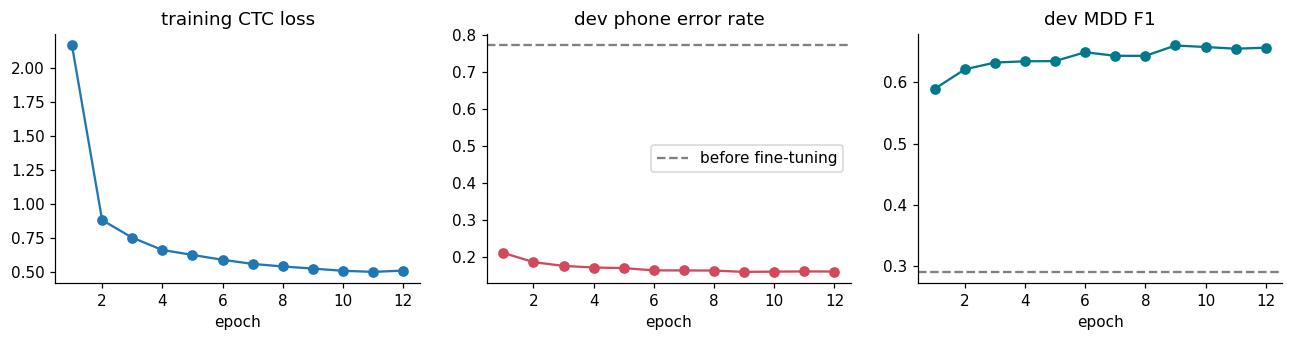

In [8]:
hist = pd.DataFrame(state["history"])
fig, axes = plt.subplots(1, 3, figsize=(12, 3.2))
axes[0].plot(hist.epoch, hist.train_loss, "o-"); axes[0].set_title("training CTC loss")
axes[1].plot(hist.epoch, hist.dev_PER, "o-", color="#d1495b"); axes[1].set_title("dev phone error rate")
axes[1].axhline(m0["PER"], ls="--", color="grey", label="before fine-tuning"); axes[1].legend()
axes[2].plot(hist.epoch, hist.dev_F1, "o-", color="#00798c"); axes[2].set_title("dev MDD F1")
axes[2].axhline(m0["f1"], ls="--", color="grey")
for ax in axes: ax.set_xlabel("epoch")
plt.tight_layout(); plt.savefig(f"{FIG}/E1_training_curves.png", dpi=200); plt.show()

## 4. Evaluation on unseen Hindi-L1 speakers: baseline vs fine-tuned, strict vs Indian-English-aware

In [9]:
best = Wav2Vec2ForCTC.from_pretrained(FT_BEST).to(DEVICE).eval()
test_pred, test_lp = predict(best, test_waves)
dev_pred, _ = predict(best, dev_waves)

base = pd.read_csv(f"{RES}/C1_baseline_predictions.csv", index_col=0).fillna("")
base_rec = {i: s.split() for i, s in base.recognised.items()}

rows = []
for split, idx, pred in [("test_hindi", test_idx, test_pred), ("dev", dev_idx, dev_pred)]:
    can, ann = meta.loc[idx, "canonical"].tolist(), meta.loc[idx, "annotated"].tolist()
    for mode, acc in [("strict", frozenset()), ("indian_aware", pc.INDIAN_ENGLISH_ACCEPT)]:
        for model_name, rec in [("baseline (pretrained)", [base_rec[i] for i in idx]), ("fine-tuned", pred)]:
            m = evaluate(can, ann, rec, acc)
            rows.append({"split": split, "mode": mode, "model": model_name, **m})
results = pd.DataFrame(rows)[["split", "mode", "model", "PER", "precision", "recall", "f1",
                              "false_rejection_rate", "diagnosis_acc"]]
results.to_csv(f"{RES}/E2_results_baseline_vs_finetuned.csv", index=False)
display(results.style.format({c: "{:.3f}" for c in results.columns[3:]}).hide(axis="index"))

meta.loc[test_idx, "recognised_ft"] = pd.Series([" ".join(p) for p in test_pred], index=test_idx)
meta.loc[dev_idx, "recognised_ft"] = pd.Series([" ".join(p) for p in dev_pred], index=dev_idx)
meta.loc[test_idx + dev_idx, ["speaker_code", "split", "text", "recognised_ft"]].to_csv(f"{RES}/E2_finetuned_predictions.csv")

Loading weights:   0%|          | 0/424 [00:00<?, ?it/s]

split,mode,model,PER,precision,recall,f1,false_rejection_rate,diagnosis_acc
test_hindi,strict,baseline (pretrained),0.231,0.364,0.492,0.419,0.137,0.628
test_hindi,strict,fine-tuned,0.155,0.527,0.501,0.514,0.072,0.763
test_hindi,indian_aware,baseline (pretrained),0.231,0.337,0.500,0.403,0.131,0.658
test_hindi,indian_aware,fine-tuned,0.155,0.513,0.510,0.511,0.064,0.788
dev,strict,baseline (pretrained),0.256,0.466,0.581,0.517,0.150,0.600
dev,strict,fine-tuned,0.159,0.684,0.638,0.660,0.067,0.745
dev,indian_aware,baseline (pretrained),0.256,0.454,0.582,0.510,0.148,0.611
dev,indian_aware,fine-tuned,0.159,0.676,0.637,0.656,0.065,0.754


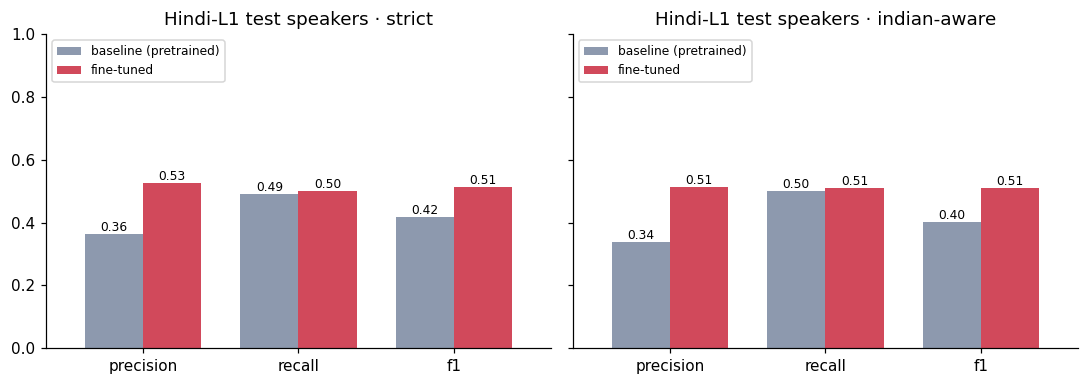

In [10]:
t = results[results.split == "test_hindi"]
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), sharey=True)
for ax, mode in zip(axes, ["strict", "indian_aware"]):
    d = t[t["mode"] == mode].set_index("model")[["precision", "recall", "f1"]]
    d.T.plot.bar(ax=ax, color=["#8d99ae", "#d1495b"], rot=0, width=0.75)
    for c in ax.containers:
        ax.bar_label(c, fmt="%.2f", fontsize=8)
    ax.set_title(f"Hindi-L1 test speakers · {mode.replace('_', '-')}"); ax.set_ylim(0, 1)
    ax.legend(fontsize=8, loc="upper left")
plt.tight_layout(); plt.savefig(f"{FIG}/E2_baseline_vs_finetuned.png", dpi=200); plt.show()

### Per speaker, and which Hindi-speaker errors the system catches
**Detection rate** = share of that annotated error the system flagged. **Diagnosis rate** = share where it also recognised exactly what was said.

In [11]:
per_spk = []
for spk in splits["test_hindi"]:
    idx = meta.index[meta.speaker_code == spk].tolist()
    pred = [test_pred[test_idx.index(i)] for i in idx]
    for mode, acc in [("strict", frozenset()), ("indian_aware", pc.INDIAN_ENGLISH_ACCEPT)]:
        m = evaluate(meta.loc[idx, "canonical"].tolist(), meta.loc[idx, "annotated"].tolist(), pred, acc)
        per_spk.append({"speaker": spk, "gender": meta.loc[idx[0], "speaker_gender"], "mode": mode,
                        "PER": m["PER"], "f1": m["f1"]})
per_spk = pd.DataFrame(per_spk).pivot(index=["speaker", "gender"], columns="mode", values=["PER", "f1"])
display(per_spk.round(3))

det = Counter(); diag = Counter(); tot = Counter()
for i, pred in zip(test_idx, test_pred):
    c, a = meta.loc[i, "canonical"], meta.loc[i, "annotated"]
    ann_r, rec_r = pc.realised_per_canonical(c, a), pc.realised_per_canonical(c, pred)
    for cc, aa, rr in zip(c, ann_r, rec_r):
        if aa != cc:
            tot[(cc, aa)] += 1; det[(cc, aa)] += rr != cc; diag[(cc, aa)] += rr == aa
err_tab = pd.DataFrame([{"expected": e, "produced": p, "count": n, "detection_rate": det[(e, p)] / n,
                         "diagnosis_rate": diag[(e, p)] / n,
                         "accepted_in_indian_mode": (e, p) in pc.INDIAN_ENGLISH_ACCEPT}
                        for (e, p), n in tot.most_common(15)])
err_tab.to_csv(f"{RES}/E3_hindi_error_detection.csv", index=False)
display(err_tab.style.format({"detection_rate": "{:.0%}", "diagnosis_rate": "{:.0%}"}).hide(axis="index"))

PER                  f1       
mode           indian_aware strict indian_aware strict
speaker gender                                        
ASI     m             0.146  0.146        0.528  0.527
RRBI    m             0.165  0.165        0.493  0.507
SVBI    f             0.142  0.142        0.526  0.526
TNI     f             0.167  0.167        0.500  0.498

expected,produced,count,detection_rate,diagnosis_rate,accepted_in_indian_mode
ð,d,250,82%,76%,False
z,s,234,63%,60%,False
ɝ,ʌ,114,64%,44%,True
ɑ,ʌ,107,98%,88%,False
eɪ,ɛ,99,11%,2%,True
oʊ,ɔ,97,24%,22%,True
d,-,90,31%,31%,False
ɑ,ɔ,89,57%,40%,True
ɹ,-,89,38%,34%,False
θ,t,84,81%,70%,False


In [12]:
def show(i, pred):
    c, a = meta.loc[i, "canonical"], meta.loc[i, "annotated"]
    ann, rec = pc.realised_per_canonical(c, a), pc.realised_per_canonical(c, pred)
    w = [max(len(x), len(y), len(z)) + 1 for x, y, z in zip(c, ann, rec)]
    f = lambda seq: "".join(s.ljust(k) for s, k in zip(seq, w))
    print(f"[{meta.loc[i, 'speaker_code']}] {meta.loc[i, 'text']}")
    print("  canonical :", f(c)); print("  annotated :", f(ann))
    print("  recognised:", f(rec))
    print("  flagged   :", "".join(("▲" if r != x else "").ljust(k) for x, r, k in zip(c, rec, w)))
    for x, r in zip(c, rec):
        if r != x and (x, r) not in pc.INDIAN_ENGLISH_ACCEPT:
            print("   →", pc.feedback_for(x, r))
    print()

shown = 0
for i, pred in zip(test_idx, test_pred):
    if 2 <= pc.edit_distance(meta.loc[i, "canonical"], meta.loc[i, "annotated"]) <= 4:
        show(i, pred); shown += 1
    if shown == 3:
        break

[ASI] will we ever forget it
  canonical : w ɪ l w i ɛ v ɝ f ɝ ɡ ɛ t ɪ t 
  annotated : w ɪ l w i æ w ɝ f ɹ ɡ ɛ t ɪ t 
  recognised: w ɪ l w i ɛ v ɝ f ɔ ɡ ɛ t ɪ t 
  flagged   :                   ▲           
   → Expected /ɝ/ but heard /ɔ/.

[ASI] and you always want to see it in the superlative degree
  canonical : ʌ n d j u ɔ l w eɪ z w ɑ n t t u s i ɪ t ɪ n ð ʌ s ʊ p ɝ l ʌ  t ɪ v d ɪ ɡ ɹ i 
  annotated : æ n d j u ɔ l w i  z w ɑ n t t u s i ɪ t ɪ n d ʌ s ʊ p ɝ l eɪ t ɪ v d ɪ ɡ ɹ i 
  recognised: æ n d j u ɔ l w eɪ z w ɑ n t t u s i ɪ t ɪ n ð ʌ s u p ʌ l eɪ t ɪ v d ɪ ɡ ɹ i 
  flagged   : ▲                                                  ▲   ▲   ▲                  
   → Expected /ʌ/ but heard /æ/.
   → For the vowel in 'book', keep it short and relaxed.
   → Expected /ʌ/ but heard /eɪ/.

[ASI] if i ever needed a fighter in my life i need one now
  canonical : ɪ f aɪ ɛ v ɝ n i d ʌ d ʌ f aɪ t ɝ ɪ n m aɪ l aɪ f aɪ n i d w ʌ n n aʊ 
  annotated : ɪ f aɪ æ w ɝ n i d ʌ d ʌ f aɪ t ɝ ɪ n m 

## Summary

In [13]:
print("Best epoch:", max(state["history"], key=lambda r: r["dev_F1"])["epoch"], "of", state["epoch"])
display(results[results.split == "test_hindi"].round(3).set_index(["mode", "model"]).drop(columns="split"))
print(f"\nFine-tuned model saved at: {FT_BEST}")
print("Notebook 3 loads it for GOP scoring, the fairness check and the app.")

Best epoch: 9 of 12


PER  precision  recall     f1  \
mode         model                                                    
strict       baseline (pretrained)  0.231      0.364   0.492  0.419   
             fine-tuned             0.155      0.527   0.501  0.514   
indian_aware baseline (pretrained)  0.231      0.337   0.500  0.403   
             fine-tuned             0.155      0.513   0.510  0.511   

                                    false_rejection_rate  diagnosis_acc  
mode         model                                                       
strict       baseline (pretrained)                 0.137          0.628  
             fine-tuned                            0.072          0.763  
indian_aware baseline (pretrained)                 0.131          0.658  
             fine-tuned                            0.064          0.788


Fine-tuned model saved at: /content/drive/MyDrive/phonolens_data/models/phonolens-ft
Notebook 3 loads it for GOP scoring, the fairness check and the app.
